# Financial Analytics Dashboard: Exploratory Data Analysis

**Goal:** understand 24 months (Jan 2024 to Dec 2025) of company finances: revenue, expenses, profit, budget performance and cash flow.

**Data:** synthetic dataset (generated with `data/generate_data.py`) covering 6 departments. Two tables: `transactions` (469 rows) and `budget` (288 rows).

**Colour code used throughout:** Revenue = blue, Expense = coral, Profit = green, Margin = amber.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
BLUE, CORAL, GREEN, AMBER = "#2E86DE", "#E8594F", "#22A67A", "#F0A500"

DATA = Path("../data")
df = pd.read_csv(DATA / "transactions.csv", parse_dates=["date"])
budget = pd.read_csv(DATA / "budget.csv", parse_dates=["date"])

print("transactions:", df.shape, "| budget:", budget.shape)
print(df.head().to_string(index=False))

transactions: (469, 6) | budget: (288, 5)
 transaction_id       date department    type        category    amount
              1 2024-01-01      Sales Revenue   Product Sales 187529.05
              2 2024-01-01      Sales Expense Marketing Spend  14889.42
              3 2024-01-01      Sales Expense Marketing Spend  19970.53
              4 2024-01-01      Sales Expense        Salaries  17961.29
              5 2024-01-01  Marketing Revenue Service Revenue  17178.78


## 1. Data quality checks

In [2]:
print("Missing values (transactions):", int(df.isna().sum().sum()))
print("Missing values (budget):      ", int(budget.isna().sum().sum()))
print("Duplicate transaction rows:   ", int(df.drop(columns="transaction_id").duplicated().sum()))
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Negative or zero amounts:     ", int((df["amount"] <= 0).sum()))
print()
print(df.groupby("type")["amount"].describe().round(0).to_string())

Missing values (transactions): 0
Missing values (budget):       0
Duplicate transaction rows:    0
Date range: 2024-01-01 to 2025-12-01
Negative or zero amounts:      0

         count     mean      std     min      25%      50%      75%       max
type                                                                         
Expense  349.0  18160.0   8638.0  5276.0  11929.0  16008.0  22566.0   51841.0
Revenue  120.0  61376.0  74446.0  4518.0   8508.0  22047.0  72343.0  257360.0


**Reading:** no missing values, no zero or negative amounts, and the dates cover exactly 24 months. The data is clean enough to analyse as is. The range of transaction sizes differs by type, which is expected (a department's monthly revenue is one large entry, while its expenses are split into 2 to 3 line items).

## 2. Monthly revenue, expense and profit

Revenue: 272,434 -> 366,912  (+34.7%)
Expense: 234,930 -> 306,254  (+30.4%)
Total revenue 7,365,086 | total expense 6,337,730 | net profit 1,027,356
Net profit 2024: 534,613 | 2025: 492,742 (-7.8%)


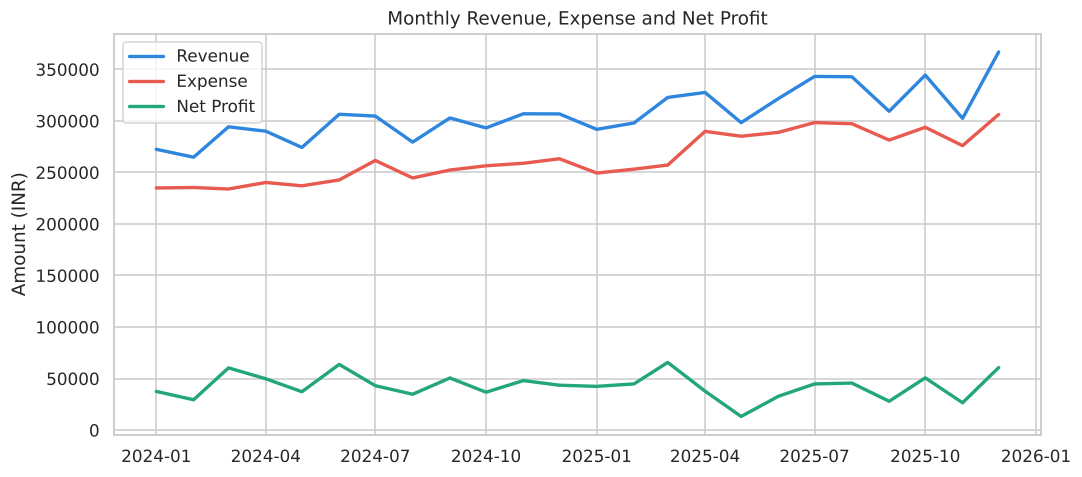

In [3]:
monthly = (df.groupby([df["date"].dt.to_period("M"), "type"])["amount"].sum().unstack().fillna(0))
monthly.index = monthly.index.to_timestamp()
monthly["Net Profit"] = monthly["Revenue"] - monthly["Expense"]
monthly["Margin %"] = monthly["Net Profit"] / monthly["Revenue"] * 100

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["Revenue"], color=BLUE, lw=2.2, label="Revenue")
ax.plot(monthly.index, monthly["Expense"], color=CORAL, lw=2.2, label="Expense")
ax.plot(monthly.index, monthly["Net Profit"], color=GREEN, lw=2.2, label="Net Profit")
ax.set_title("Monthly Revenue, Expense and Net Profit")
ax.set_ylabel("Amount (INR)")
ax.legend()
plt.tight_layout(); plt.show()

first, last = monthly["Revenue"].iloc[0], monthly["Revenue"].iloc[-1]
print(f"Revenue: {first:,.0f} -> {last:,.0f}  (+{(last/first-1)*100:.1f}%)")
print(f"Expense: {monthly['Expense'].iloc[0]:,.0f} -> {monthly['Expense'].iloc[-1]:,.0f}  (+{(monthly['Expense'].iloc[-1]/monthly['Expense'].iloc[0]-1)*100:.1f}%)")
print(f"Total revenue {monthly['Revenue'].sum():,.0f} | total expense {monthly['Expense'].sum():,.0f} | net profit {monthly['Net Profit'].sum():,.0f}")
p24 = monthly.loc["2024", "Net Profit"].sum(); p25 = monthly.loc["2025", "Net Profit"].sum()
print(f"Net profit 2024: {p24:,.0f} | 2025: {p25:,.0f} ({(p25/p24-1)*100:+.1f}%)")

**Reading:** revenue rises steadily (+34.7%), but expenses rise almost as fast (+30.4%), so profit stays positive without growing. Profit in 2025 was about 8% lower than in 2024. Costs are keeping pace with revenue instead of scaling slower than it.

Average monthly margin: 13.9%
Overall margin (total profit / total revenue): 13.9%
Best month : Jun 2024 (20.8%)
Worst month: May 2025 (4.4%)


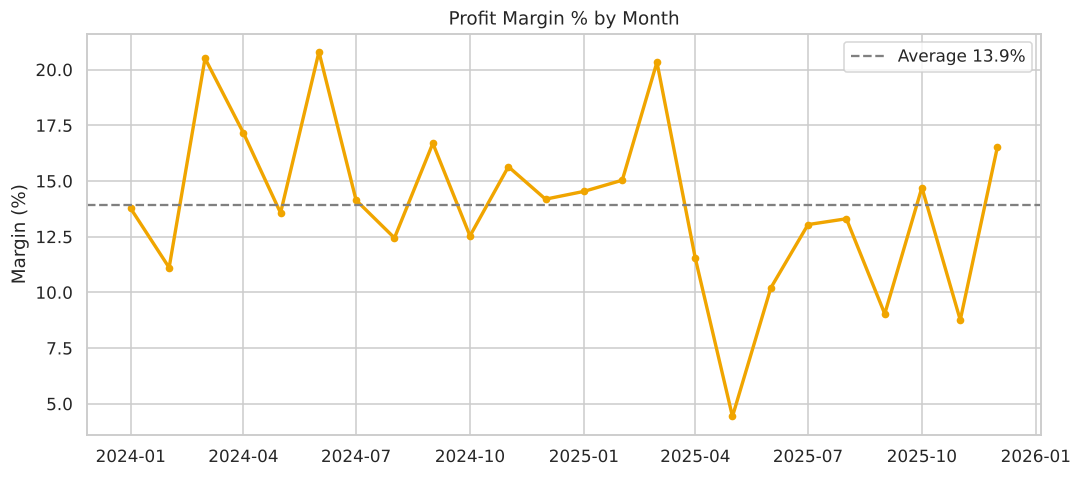

In [4]:
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["Margin %"], color=AMBER, lw=2.2, marker="o", ms=4)
ax.axhline(monthly["Margin %"].mean(), color="grey", ls="--", label=f"Average {monthly['Margin %'].mean():.1f}%")
ax.set_title("Profit Margin % by Month")
ax.set_ylabel("Margin (%)")
ax.legend()
plt.tight_layout(); plt.show()

print(f"Average monthly margin: {monthly['Margin %'].mean():.1f}%")
print(f"Overall margin (total profit / total revenue): {monthly['Net Profit'].sum()/monthly['Revenue'].sum()*100:.1f}%")
print(f"Best month : {monthly['Margin %'].idxmax():%b %Y} ({monthly['Margin %'].max():.1f}%)")
print(f"Worst month: {monthly['Margin %'].idxmin():%b %Y} ({monthly['Margin %'].min():.1f}%)")

**Reading:** margin is volatile, swinging between about 4% and 21%, because a single month's expenses can jump while revenue lags. The average is about 14%.

## 3. Where the money comes from and goes

Top expense category: Logistics (15.2% of expenses)
Top four categories share: 59.6% of expenses
Top revenue department: Sales (65.6% of revenue)


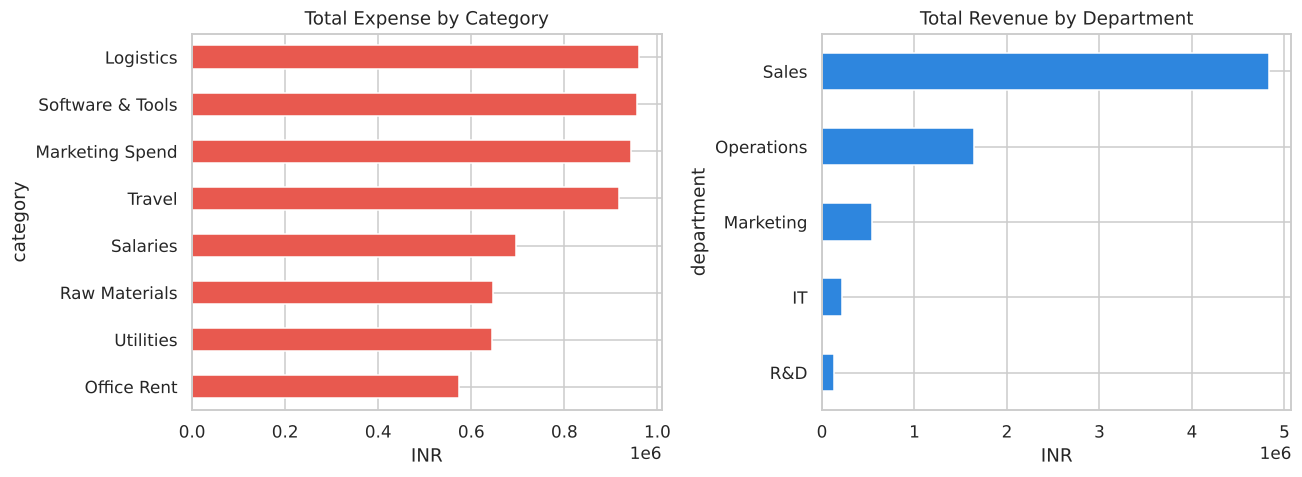

In [5]:
exp_cat = df[df["type"] == "Expense"].groupby("category")["amount"].sum().sort_values()
rev_dept = df[df["type"] == "Revenue"].groupby("department")["amount"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
exp_cat.plot.barh(ax=axes[0], color=CORAL)
axes[0].set_title("Total Expense by Category"); axes[0].set_xlabel("INR")
rev_dept.plot.barh(ax=axes[1], color=BLUE)
axes[1].set_title("Total Revenue by Department"); axes[1].set_xlabel("INR")
plt.tight_layout(); plt.show()

print("Top expense category:", exp_cat.idxmax(), f"({exp_cat.max()/exp_cat.sum()*100:.1f}% of expenses)")
print(f"Top four categories share: {exp_cat.nlargest(4).sum()/exp_cat.sum()*100:.1f}% of expenses")
print("Top revenue department:", rev_dept.idxmax(), f"({rev_dept.max()/rev_dept.sum()*100:.1f}% of revenue)")

**Reading:** Sales produces about two thirds of all revenue, which is a concentration risk. Expenses are spread fairly evenly across the top four categories (Logistics, Software and Tools, Marketing Spend, Travel), so no single category dominates cost.

## 4. Budget vs actual

               actual     budget  months_over  overspend_%
department                                                
R&D          968979.3   936600.0           13          3.5
Marketing    818755.5   802800.0           13          2.0
IT           706826.2   695760.0           13          1.6
HR           595819.6   588720.0           11          1.2
Sales       1489387.9  1471800.0           10          1.2
Operations  1757961.7  1739400.0           15          1.1
Actual expense growth : 1.16% per month (compounded)
Budgeted expense growth: 0.90% per month (compounded)


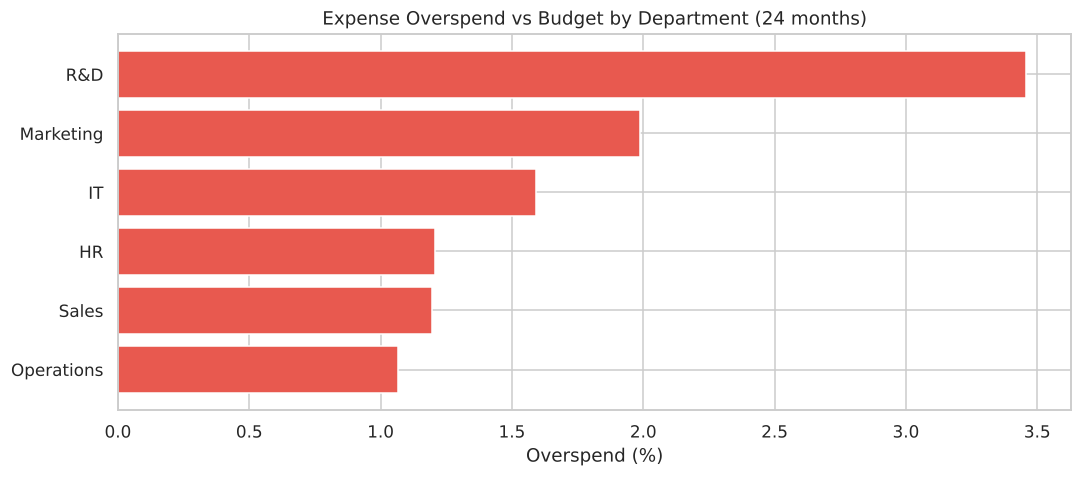

In [6]:
actual = (df[df["type"] == "Expense"].groupby(["date", "department"])["amount"].sum().rename("actual"))
bud = (budget[budget["type"] == "Expense"].groupby(["date", "department"])["budgeted_amount"].sum().rename("budget"))
bva = pd.concat([actual, bud], axis=1).reset_index()
bva["over"] = bva["actual"] > bva["budget"]

summary = bva.groupby("department").agg(actual=("actual", "sum"), budget=("budget", "sum"),
                                         months_over=("over", "sum"))
summary["overspend_%"] = (summary["actual"] / summary["budget"] - 1) * 100
summary = summary.sort_values("overspend_%", ascending=False)
print(summary.round(1).to_string())

fig, ax = plt.subplots()
ax.barh(summary.index[::-1], summary["overspend_%"][::-1], color=CORAL)
ax.set_title("Expense Overspend vs Budget by Department (24 months)")
ax.set_xlabel("Overspend (%)")
plt.tight_layout(); plt.show()

# Do budgets assume slower cost growth than actually happened?
act_m = bva.groupby("date")["actual"].sum(); bud_m = bva.groupby("date")["budget"].sum()
n = len(act_m) - 1
print(f"Actual expense growth : {((act_m.iloc[-1]/act_m.iloc[0])**(1/n)-1)*100:.2f}% per month (compounded)")
print(f"Budgeted expense growth: {((bud_m.iloc[-1]/bud_m.iloc[0])**(1/n)-1)*100:.2f}% per month (compounded)")

**Reading:** every department spent more than its budget over the period, and each exceeded its monthly budget in 10 to 15 of the 24 months. R&D has the largest overspend (3.5%), and Operations is over budget most often (15 of 24 months). The overspends are small in size but persistent, and actual cost growth (about 1.2% a month) outpaces what the budgets assume (about 0.9%). That points to budgets set too low, rather than one team overspending.

## 5. Cumulative cash flow

Cumulative net cash flow after 24 months: 1,027,356


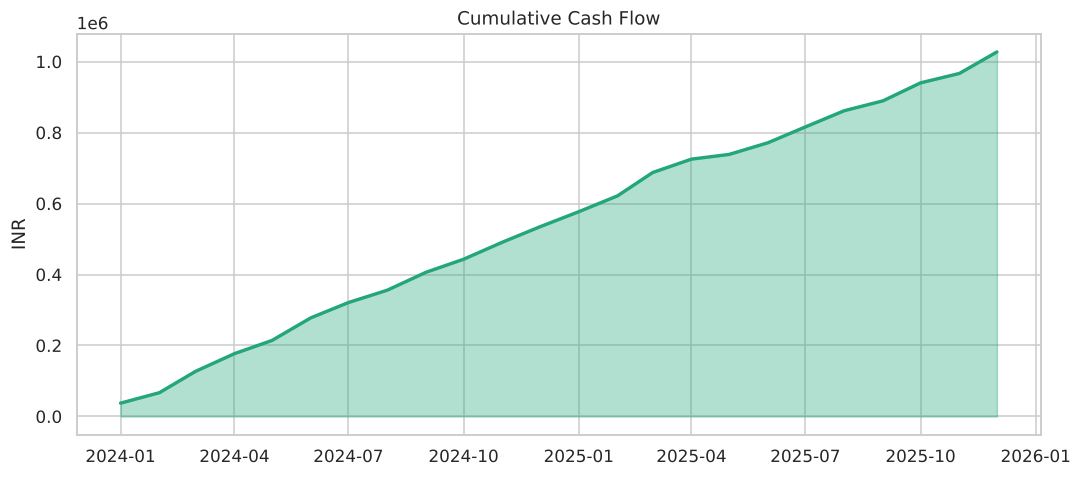

In [7]:
monthly["Cumulative Cash Flow"] = monthly["Net Profit"].cumsum()
fig, ax = plt.subplots()
ax.fill_between(monthly.index, monthly["Cumulative Cash Flow"], color=GREEN, alpha=0.35)
ax.plot(monthly.index, monthly["Cumulative Cash Flow"], color=GREEN, lw=2.2)
ax.set_title("Cumulative Cash Flow")
ax.set_ylabel("INR")
plt.tight_layout(); plt.show()
print(f"Cumulative net cash flow after 24 months: {monthly['Cumulative Cash Flow'].iloc[-1]:,.0f}")

## Key takeaways

1. **Growth:** revenue grew about 34.7% over 24 months, but expenses grew nearly as fast (+30.4%), so profit did not grow (2025 was about 8% below 2024) and margin averaged about 14%.
2. **Concentration:** Sales generates about two thirds of revenue.
3. **Budgeting gap:** all six departments overspent their expense budgets. R&D has the largest overspend (3.5%) and Operations was over budget most often (15 of 24 months).
4. **Recommendation:** re-baseline department budgets to actual cost growth (about 1.2% per month against about 0.9% assumed in budgets), starting with R&D and Operations.

These findings feed the Tableau dashboard (see `tableau_setup/TABLEAU_GUIDE.md`).